<a href="https://colab.research.google.com/github/MarcoLuw/QoE-MOS-Prediction/blob/main/model_training/random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature description

| # | Column | Category | Meaning / Practical Use | Values / Details from README |
|---|--------|----------|--------------------------|------------------------------|
| 1 | id | Identifier | Unique identifier of the sample (one video-viewing test record). | Not further defined in README |
| 2 | user_id | Identifier | Identifier of the tester who performed the session; links multiple samples to the same person. | Not further defined in README |
| 3 | QoA_VLCresolution | Video (QoA) | The actual picture resolution at which the video was played in VLC during the session, i.e. how many vertical lines of detail were rendered on screen. In practice it tells you whether the user watched a lower-detail or higher-detail version of the clip. | README notes resolution is a class identifier with values 240p and 360p |
| 4 | QoA_VLCbitrate | Video (QoA) | The video bitrate reported by VLC, i.e. the amount of video data per second during playback; higher values mean more data and generally better image quality. | Not further defined in README |
| 5 | QoA_VLCframerate | Video (QoA) | The playback frame rate reported by VLC, i.e. how many video frames per second were shown; relates to motion smoothness. | Not further defined in README |
| 6 | QoA_VLCdropped | Video (QoA) | The count of video frames dropped by VLC during playback; a measure of rendering/decoding loss experienced by the user. | Not further defined in README |
| 7 | QoA_VLCaudiorate | Video (QoA) | The audio bitrate/rate reported by VLC for the session's sound track. | Not further defined in README |
| 8 | QoA_VLCaudioloss | Video (QoA) | The amount of audio lost during playback as reported by VLC; relates to sound dropouts. | Not further defined in README |
| 9 | QoA_BUFFERINGcount | Video (QoA) | The number of buffering (stalling) events that occurred during the video session; how many times playback paused to rebuffer. | Not further defined in README |
| 10 | QoA_BUFFERINGtime | Video (QoA) | The total time spent buffering/stalling during the session; the cumulative duration playback was interrupted. | Not further defined in README |
| 11 | QoS_type | Network (QoS) | The mobile network access technology used during the test. | Coded: 1=EDGE, 2=UMTS, 3=HSPA, 4=HSPAP, 5=LTE |
| 12 | QoS_operator | Network (QoS) | The French mobile network operator used for the session. | Coded: 1=SFR, 2=BOUYGUES, 3=ORANGE, 4=FREE |
| 13 | QoD_model | Device (QoD) | The model of the device (phone or tablet) used by the tester. | Not further defined in README |
| 14 | QoD_os-version | Device (QoD) | The Android OS version running on the test device. | Not further defined in README |
| 15 | QoD_api-level | Device (QoD) | The Android API level of the device (the platform API number associated with the OS version). | Not further defined in README |
| 16 | QoU_sex | User (QoU) | The tester's gender. | Coded: 0=Woman, 1=Man |
| 17 | QoU_age | User (QoU) | The tester's age. | README states testers were aged 19 to 38 |
| 18 | QoU_study | User (QoU) | The tester's highest education level. | Coded: 5=University, 4=Secondary school, 3=College, 2=Primary school, 1=Other |
| 19 | QoF_begin_time | Feedback (QoF) | The begin time of the video session (when the viewing started). | Not further defined in README |
| 20 | QoF_shift | Feedback (QoF) | A shift value related to the session. | Not further defined in README |
| 21 | QoF_audio | Feedback (QoF) | User feedback relating to the audio of the session. | Not further defined in README |
| 22 | QoF_video | Feedback (QoF) | User feedback relating to the video of the session. | Not further defined in README |
| 23 | MOS | Target / Score | Mean Opinion Score the tester gives at the end of each video view; the subjective quality rating used as the label. | Coded: 5=Excellent, 4=Good, 3=Fair, 2=Poor, 1=Bad |

# Download dataset

GitHub Link: https://github.com/Lamyne/Poqemon-QoE-Dataset

In [1]:
!wget https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv -O ~/pokemon.csv
# !wget https://raw.githubusercontent.com/andreaaraldo/machine-learning-for-networks/master/course_library/visualization.py

--2026-11-09 14:26:34--  https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8002::154, 2606:50c0:8001::154, 2606:50c0:8000::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8002::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 158675 (155K) [text/plain]
Saving to: ‘/mnt/hdd/homes/hlu/pokemon.csv’

/mnt/hdd/homes/hlu/ 100%[===================>] 154.96K  --.-KB/s    in 0.04s   

2026-11-09 14:26:34 (4.06 MB/s) - ‘/mnt/hdd/homes/hlu/pokemon.csv’ saved [158675/158675]



In [2]:
!ls

knn_regression.ipynb  random_forest.ipynb  xgboost_regression.ipynb


# Python package import

In [3]:
import pandas as pd
import numpy as np
# import visualization
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix

from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# The following is to be able to mount Google Drive
# from google.colab import drive
import pickle # To save the model
from os.path import isfile

In [4]:
FEATURES = ["QoA_VLCresolution", "QoA_VLCbitrate", "QoA_VLCframerate",
            "QoA_VLCdropped", "QoA_VLCaudiorate", "QoA_VLCaudioloss",
            "QoA_BUFFERINGcount", "QoA_BUFFERINGtime"]
TARGET = "MOS"

In [5]:
df = pd.read_csv("~/pokemon.csv")

In [6]:
df.head()

,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
0,590,71,360,528.39294,24.950000,0,43.800000,0,2,683,...,4.1.1(122573.16),16,1,20,5,3,5,3,4,3
1,428,46,360,402.64664,30.066667,0,44.200000,0,2,690,...,4.4.2(I9195XXUCNK1),19,1,25,5,4,5,5,5,5
2,406,44,360,735.84070,24.200000,0,44.183333,0,2,840,...,4.1.2(I9300XXELL4),16,1,22,5,3,5,4,4,4
3,1256,133,240,529.48830,24.116667,9,43.850000,0,2,868,...,4.4.4(suv3Rw),19,1,31,5,4,5,5,5,5
4,244,22,360,736.00085,24.066667,0,43.850000,0,2,869,...,4.1.2(I9300XXELL4),16,0,26,5,5,5,4,5,5


# Data Preprocessing

- Remove duplications
- Remove error values
- Handle missing values

In [7]:
def preprocess(df):
  df = df.drop_duplicates(keep="first") # drop duplications
  df = df[df["QoA_VLCresolution"] != 16]  # drop error values
  df = df.dropna(subset=FEATURES + [TARGET]) # drop missing values
  df = df.reset_index(drop=True)

  X = df[FEATURES]
  y = df[TARGET]
  return X, y

# Prepare data

In [8]:
def prepare_data(X, y):
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42
  )

  # feature engineering: transform (de-skew) - optional
  # pt = PowerTransformer(method="yeo-johnson")
  # X_train = pt.fit_transform(X_train)
  # X_test = pt.transform(X_test)

  # scale - ESSENTIAL for KNN (distance-based; features must share a scale)
  scaler = StandardScaler()
  X_train = scaler.fit_transform(X_train)
  X_test = scaler.transform(X_test)

  return X_train, X_test, y_train, y_test, scaler

In [9]:
X, y = preprocess(df)
X_train, X_test, y_train, y_test, scaler = prepare_data(X, y)

# Training a KNN model

## Define grid params

In [10]:
# number of neighbors to vote (the key KNN knob)
n_neighbors = [3, 5, 7, 9, 11, 15, 21, 31]

# how neighbors are weighted: equally, or closer = more influence
weights = ['uniform', 'distance']

# distance metric power: 1 = Manhattan, 2 = Euclidean
p = [1, 2]

# algorithm to compute neighbors
algorithm = ['auto', 'ball_tree', 'kd_tree', 'brute']

# leaf size for tree-based neighbor search
leaf_size = [10, 20, 30, 40, 50]

grid_param = {
    'n_neighbors': n_neighbors,
    'weights': weights,
    'p': p,
    'algorithm': algorithm,
    'leaf_size': leaf_size,
}

## Random Grid Search

The grid above spans many combinations x 5 k-fold.

`RandomizedSearchCV` helps to overcome the hurdle by randomly sampling a specified number of possible candidate models.

For example, only randomly sample 200 models.

In [21]:
# The search parallelizes across 200x5 fits (all CPUs) (n_jobs = -1)
# while each individual model trains single-threaded (n_jobs = 1)
regressor = KNeighborsRegressor(n_jobs=1)
search = RandomizedSearchCV(
                            scoring='neg_root_mean_squared_error',
                            estimator=regressor,
                            param_distributions=grid_param,
                            n_iter=500, # We just test 200 configurations
                            verbose=2,
                            random_state=42, # Random state of GridSearch only
                            n_jobs=-1, # Train models in parallel using all CPUs
                            cv=5 # 5-fold validation
                          )

In [22]:
search.fit(X_train, y_train)

Fitting 5 folds for each of 500 candidates, totalling 2500 fits

[CV] END algorithm=auto, leaf_size=20, n_neighbors=21, p=1, weights=uniform; total time=   0.0s
[CV] END algorithm=kd_tree, leaf_size=30, n_neighbors=5, p=2, weights=uniform; total time=   0.0s
[CV] END algorithm=kd_tree, leaf_size=30, n_neighbors=5, p=2, weights=uniform; total time=   0.0s
[CV] END algorithm=kd_tree, leaf_size=30, n_neighbors=5, p=2, weights=uniform; total time=   0.0s
[CV] END algorithm=ball_tree, leaf_size=20, n_neighbors=11, p=1, weights=uniform; total time=   0.0s
[CV] END algorithm=ball_tree, leaf_size=20, n_neighbors=11, p=1, weights=uniform; total time=   0.0s
[CV] END algorithm=ball_tree, leaf_size=20, n_neighbors=11, p=1, weights=uniform; total time=   0.0s
[CV] END algorithm=ball_tree, leaf_size=20, n_neighbors=11, p=1, weights=uniform; total time=   0.0s
[CV] END algorithm=ball_tree, leaf_size=20, n_neighbors=11, p=1, weights=uniform; total time=   0.0s
[CV] END algorithm=ball_tree, leaf_size=

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsRegressor(n_jobs=1)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'algorithm': ['auto', 'ball_tree', ...], 'leaf_size': [10, 20, ...], 'n_neighbors': [3, 5, ...], 'p': [1, 2], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",500
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whic

## Get best model

In [23]:
print(search.best_params_)
best_model = search.best_estimator_

{'weights': 'uniform', 'p': 2, 'n_neighbors': 9, 'leaf_size': 10, 'algorithm': 'ball_tree'}


With this best model, we try to (re)train it on the whole dataset

In [24]:
best_model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",9
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'ball_tree'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",10
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


# Evaluating Model

In [25]:
y_pred = best_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("MAE :", mae)
print("R2  :", r2)

RMSE: 0.7858775857901643
MAE : 0.5544768069039913
R2  : 0.4653143822772431

[CV] END algorithm=kd_tree, leaf_size=30, n_neighbors=11, p=2, weights=uniform; total time=   0.0s
[CV] END algorithm=kd_tree, leaf_size=30, n_neighbors=11, p=2, weights=uniform; total time=   0.0s
[CV] END algorithm=brute, leaf_size=20, n_neighbors=7, p=1, weights=distance; total time=   0.0s
[CV] END algorithm=brute, leaf_size=20, n_neighbors=7, p=1, weights=distance; total time=   0.0s
[CV] END algorithm=kd_tree, leaf_size=10, n_neighbors=15, p=2, weights=uniform; total time=   0.0s
[CV] END algorithm=auto, leaf_size=20, n_neighbors=15, p=1, weights=distance; total time=   0.0s
[CV] END algorithm=auto, leaf_size=50, n_neighbors=3, p=1, weights=distance; total time=   0.0s
[CV] END algorithm=auto, leaf_size=50, n_neighbors=3, p=1, weights=distance; total time=   0.0s
[CV] END algorithm=ball_tree, leaf_size=10, n_neighbors=21, p=2, weights=uniform; total time=   0.0s
[CV] END algorithm=ball_tree, leaf_size=10,

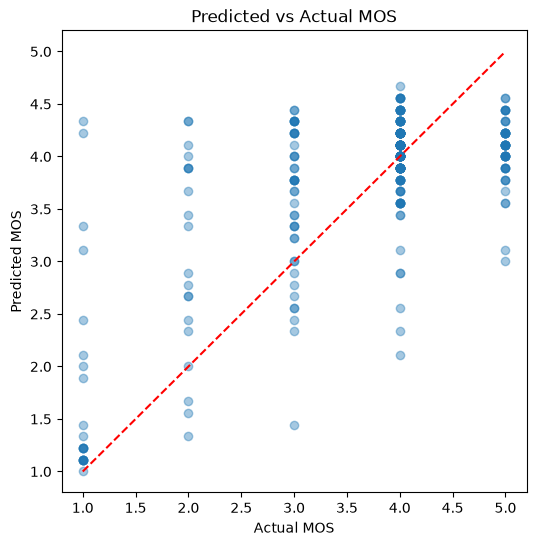

In [16]:
# Predicted vs actual MOS
title = "Predicted vs Actual MOS"
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

# diagonal reference line (perfect prediction)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--')

plt.xlabel("Actual MOS")
plt.ylabel("Predicted MOS")
plt.title(title)
plt.show()

# Save model

## On Google Colab

In [17]:
# mount_point = '/content/drive'
# drive.mount(mount_point, force_remount=True)
# drive_path = mount_point + '/My Drive/'

# save_path = drive_path + 'Colab Notebooks/TSP - Data Science/Project/Models/'
# filename = save_path + f'KNN.pkl'
# pickle.dump(best_model, open(filename, 'wb'))

In [18]:
%cd $save_path
!ls

[Errno 2] No such file or directory: '$save_path'
/mnt/hdd/homes/hlu/QoE-MOS-Prediction/model_training
knn_regression.ipynb  random_forest.ipynb  xgboost_regression.ipynb


Optional: create a function to reduce duplication

In [19]:
# def search_or_load(model_filename, search, X_train, y_train):
#   if (isfile(model_filename)):
#     print("Loading model")
#     model = pickle.load(open(model_filename, 'rb'))

#   else:
#     print("Searching the best hyper_parameters")
#     search.fit(X_train, y_train)
#     print(search.best_params_)
#     model = search.best_estimator_
#     print("Training model")
#     model.fit(X_train,y_train)
#     pickle.dump(model, open(model_filename, 'wb'))
#     print("Model saved in in file ", model_filename)
#   return model

## On Linux

In [20]:
from pathlib import Path
from datetime import datetime

model_tag = "KNN"
model_artifact = f'{model_tag}.pkl'

# Timestamp for this run, to avoid overwriting previous runs
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Always under home, in a dedicated results folder
SAVE_PATH = Path.home() / "ds_result" / timestamp
SAVE_PATH.mkdir(parents=True, exist_ok=True)

FINAL_MODEL_PATH = str(SAVE_PATH / model_artifact)

pickle.dump(best_model, open(FINAL_MODEL_PATH, 'wb'))

print("Final model path:", FINAL_MODEL_PATH)

Final model path: /mnt/hdd/homes/hlu/ds_result/20261109_142641/KNN.pkl
